# 07 - Safety cars

The race simulator needs to know how likely a safety car or virtual safety car (VSC) is on any lap, because a pit stop under a safety car costs much less than one under green flags. This notebook builds a simple model for that. It only uses 2022 to 2024, and wet and drying races are left out, same as the lap-time models.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from f1lab.features import drying_races, wet_races
from f1lab.safety_car import Hazard, hazard_table, lap_status, log_loss, neutralisation_events

raw = pd.read_parquet("../data/laps.parquet")
clean = pd.read_parquet("../data/laps_clean.parquet")
skip = drying_races(clean) | wet_races(raw)
lap = lap_status(raw, skip)
lap = lap[lap["season"] <= 2024]        # 2025 stays out until the final test
events = neutralisation_events(lap)
table = hazard_table(lap)
print(f"{lap.groupby(['season', 'round']).ngroups} dry races, {len(events)} safety car / VSC periods, {len(table)} laps at risk")

59 dry races, 61 safety car / VSC periods, 3265 laps at risk


## What the events look like

In [2]:
per_race = events.groupby(["season", "round"]).size().reindex(lap.groupby(["season", "round"]).size().index, fill_value=0)
print("events per race:", per_race.value_counts().sort_index().to_dict(), f"(mean {per_race.mean():.2f})")
print(f"races with at least one: {(per_race > 0).mean():.0%}")
print()
print(events.groupby("kind")["length"].describe()[["count", "mean", "50%", "max"]].round(1))
print("\nevents by season:", events.groupby("season").size().to_dict())

events per race: {0: 20, 1: 20, 2: 16, 3: 3} (mean 1.03)
races with at least one: 66%

      count  mean  50%   max
kind                        
sc     35.0   4.9  5.0  10.0
vsc    26.0   2.5  2.0   6.0

events by season: {2022: 27, 2023: 21, 2024: 13}


That's about one event per race. 20 races had none, 20 had one, 16 had two and 3 had three, so roughly two thirds of races had at least one. Safety cars last about five laps (up to ten) and VSCs about two (up to six). The count moves around a lot from year to year: 27 events in 2022, 21 in 2023 and 13 in 2024.

chance a neutralisation starts on lap 1 or 2: 0.124 per lap
chance on any later lap:                      0.015 per lap


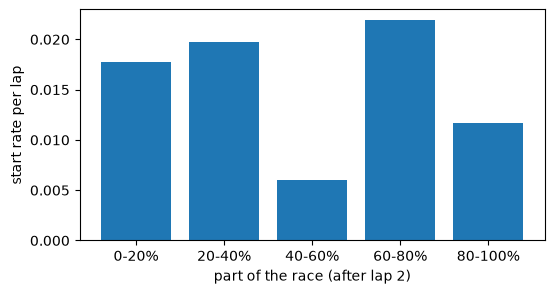

,mean,size
"(0.0, 0.2]",0.0178,507
"(0.2, 0.4]",0.0197,659
"(0.4, 0.6]",0.0060,668
"(0.6, 0.8]",0.0219,640
"(0.8, 1.0]",0.0117,686


In [3]:
early = table["early"]
print(f"chance a neutralisation starts on lap 1 or 2: {table[early]['event'].mean():.3f} per lap")
print(f"chance on any later lap:                      {table[~early]['event'].mean():.3f} per lap")
stage = pd.cut(table[~early]["lap"] / table[~early]["race_laps"], [0, .2, .4, .6, .8, 1])
rate_by_stage = table[~early].groupby(stage, observed=True)["event"].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(range(5), rate_by_stage["mean"])
ax.set_xticks(range(5), ["0-20%", "20-40%", "40-60%", "60-80%", "80-100%"])
ax.set_xlabel("part of the race (after lap 2)"); ax.set_ylabel("start rate per lap")
plt.show()
rate_by_stage.round(4)

The first two laps are by far the riskiest, at 0.124 per lap against 0.015 for any later lap. That's first-lap incidents. After lap 2 the rate looks flat through the race. The dip between 40 and 60% is probably noise, there just aren't many events.

## Which model?

In [4]:
def stage_model(train, test):
    edges = [0, .2, .4, .6, .8, 1]
    late = train[~train["early"]]
    by = late.groupby(pd.cut(late["lap"] / late["race_laps"], edges), observed=True)["event"].mean()
    p = pd.cut(test["lap"] / test["race_laps"], edges).map(by).astype(float).fillna(late["event"].mean())
    return np.where(test["early"], train[train["early"]]["event"].mean(), p)

def evaluate(name, predict):
    losses, miss = [], []
    for season in (2022, 2023, 2024):
        train, test = table[table["season"] != season], table[table["season"] == season]
        p = predict(train, test)
        losses.append(log_loss(test["event"], p))
        miss.append(abs(p.sum() - test["event"].sum()) / test.groupby("round").ngroups)
    return {"model": name, "log loss": np.mean(losses), "events/race off by": np.mean(miss)}

rows = [
    evaluate("one rate for every lap", lambda tr, te: np.full(len(te), tr["event"].mean())),
    evaluate("separate rate for laps 1-2", lambda tr, te: Hazard().fit(tr).predict(te)),
    evaluate("laps 1-2, then rate by race stage", stage_model),
]
for k in (0.5, 1, 2, 4, 8, 16):
    rows.append(evaluate(f"laps 1-2 plus track effect (k={k})", lambda tr, te, k=k: Hazard(k=k).fit(tr).predict(te)))
results = pd.DataFrame(rows).set_index("model")
results.round(4)

,log loss,events/race off by
model,,
one rate for every lap,0.0974,0.4884
separate rate for laps 1-2,0.0932,0.4819
"laps 1-2, then rate by race stage",0.0958,0.4825
laps 1-2 plus track effect (k=0.5),0.0933,0.4669
laps 1-2 plus track effect (k=1),0.0925,0.4682
laps 1-2 plus track effect (k=2),0.0922,0.4721
laps 1-2 plus track effect (k=4),0.0923,0.4755
laps 1-2 plus track effect (k=8),0.0926,0.4780
laps 1-2 plus track effect (k=16),0.0929,0.4797


I compared a few models by holding out one season at a time and scoring how well each one predicted the events in the season it hadn't seen (log loss, lower is better). Giving the first two laps their own rate is the big win, 0.0974 down to 0.0932. A rate by race stage makes it worse (0.0958), so there's nothing real in the stage pattern. A per-track multiplier helps by a hair at its best setting (0.0922 with k=2), which is about a 1% gain on a small sample.

## The one I picked

In [5]:
hz = Hazard().fit(table)   # rate for laps 1-2, one rate after that, no track effect
print(f"rate on laps 1-2: {hz.rate_early_:.3f} per lap | later laps: {hz.rate_late_:.4f} per lap")
for laps in (50, 57, 70):
    print(f"{laps}-lap race: about {hz.rate_early_ * 2 + hz.rate_late_ * (laps - 2):.2f} safety car / VSC starts")

rate on laps 1-2: 0.124 per lap | later laps: 0.0152 per lap
50-lap race: about 0.98 safety car / VSC starts
57-lap race: about 1.08 safety car / VSC starts
70-lap race: about 1.28 safety car / VSC starts


I went with the simple model: 0.124 per lap on laps 1 and 2 and 0.015 per lap after that. For a 57-lap race that's about 1.1 starts.

In [6]:
# Does a model get the number of events per race about right on a season it didn't train on?
# Each model's rate is applied to every lap of the race. (The at-risk table can't be used
# for this: a race with a long safety car loses its at-risk laps, which would bias the check.)
races = lap.groupby(["season", "round"]).agg(track=("track", "first"), race_laps=("lap_number", "max")).reset_index()
races = races.merge(events.groupby(["season", "round"]).size().rename("actual").reset_index(), how="left", on=["season", "round"]).fillna({"actual": 0})

def expected_events(h, race):
    return h.rate_early_ * 2 + sum(h.rate(l, race.track) for l in range(3, int(race.race_laps) + 1))

def check(k):
    out = []
    for season in (2022, 2023, 2024):
        h = Hazard(k=k).fit(table[table["season"] != season])
        te = races[races["season"] == season]
        out.append(te.assign(expected=[expected_events(h, r) for r in te.itertuples()]))
    return pd.concat(out)

summary = {}
for name, k in (("laps 1-2 only", None), ("plus track effect (k=2)", 2), ("plus track effect (k=8)", 8)):
    c = check(k)
    summary[name] = {"expected per race": c["expected"].mean(), "actual per race": c["actual"].mean(),
                     "rank correlation": c["expected"].corr(c["actual"], method="spearman"),
                     "mean abs error": (c["expected"] - c["actual"]).abs().mean()}
pd.DataFrame(summary).T.round(3)

,expected per race,actual per race,rank correlation,mean abs error
laps 1-2 only,1.143,1.034,-0.277,0.845
plus track effect (k=2),1.140,1.034,-0.037,0.827
plus track effect (k=8),1.139,1.034,-0.176,0.830


Then I checked whether any version can say *which* races will have safety cars. I applied each model's rate to every lap of a held-out race and compared the expected count with what happened. None of them can. The rank correlation between expected and actual is negative for the simple model (-0.28) and about zero with the track effect (-0.04).

In [7]:
c = check(None)
c.groupby(pd.qcut(c["race_laps"], 3), observed=True).agg(
    races=("actual", "size"), laps=("race_laps", "mean"), expected=("expected", "mean"), actual=("actual", "mean")
).round(2)

,races,laps,expected,actual
race_laps,,,,
"(43.999, 56.0]",23,51.26,1.01,0.96
"(56.0, 62.667]",16,58.00,1.14,1.19
"(62.667, 78.0]",20,70.05,1.29,1.00


The averages are close (1.14 expected against 1.03 actual), but the number of events doesn't follow race length. The longest third of races averaged 1.00 events, below the 1.29 the model expects. With about 20 races in each group that's within noise, but I'd treat this as a decent average rate and nothing more.

I'm keeping the version without the track effect. It's simpler, and the track effect doesn't predict anything on seasons it hasn't seen.

One thing I got wrong along the way: my first version of this check only used the laps that were at risk. A race with a long safety car loses at-risk laps, so its expected count drops while its actual count is high, and that produced a strong negative correlation that wasn't real. Applying the model to every lap of the race fixed it.